In [1]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

In [ ]:
from scripts_.stitching_vk_data import plot_stitched_height_image_from_vk #, plot_stitched_height_image_from_vk_2
from scripts_.tilt_correction import baseplane_filter
from scripts_.plot_vk_data import plot_vk4_height, plot_vk4_reflected_light
from scripts_.load_vk_data import parse_vk6_file, parse_vk4_file
from scripts_.preprocess_vk_data import crop_Vk4File_map
from scripts_.feature_enhancement import feature_enhancement_morphological#, feature_enhancement, feature_enhancement_masked

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

In [17]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y1_X1.vk4")

with open(file_name, 'rb') as f:
    data_1_vk4 = parse_vk4_file(f)


ax = plot_vk4_height(data_1_vk4, data_type='original')
plt.plot()

FileNotFoundError: [Errno 2] No such file or directory: '..\\raw_data_vk\\Sample 3 Milan full\\Stitched 50x small area\\20260617173422_Y1_X1.vk4'

[]

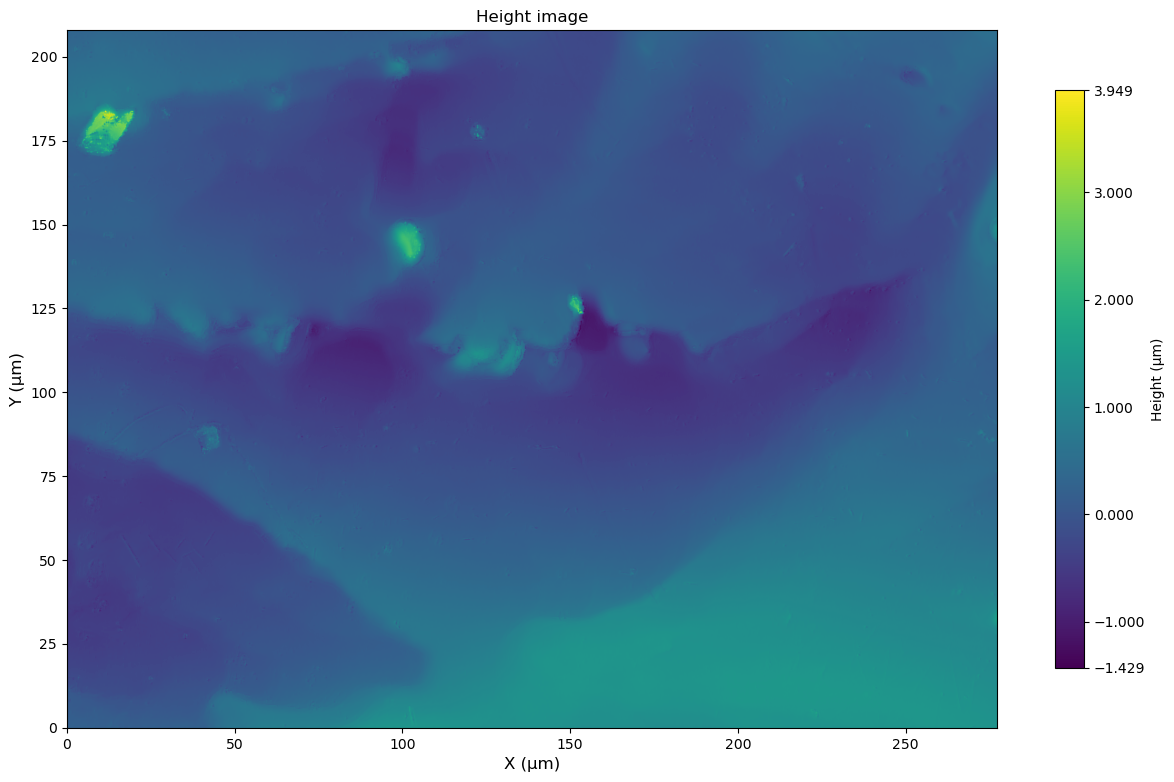

In [ ]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y1_X1.vk4")

with open(file_name, 'rb') as f:
    data_1_vk4 = parse_vk4_file(f)


data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, 60)

ax = plot_vk4_height(data_1_vk4_tiltcorr, data_type='baseplane_subtracted')
plt.plot()

[]

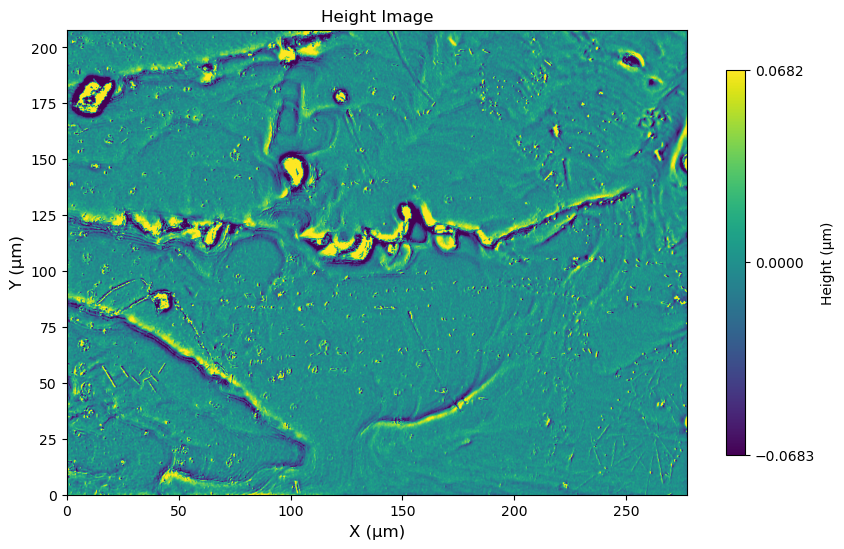

In [ ]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y1_X1.vk4")

with open(file_name, 'rb') as f:
    data_1_vk4 = parse_vk4_file(f)


data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, 60)
data_1_vk4_enhanced = feature_enhancement(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')
#plt.savefig('plot group meeting height.jpeg')
plt.plot()

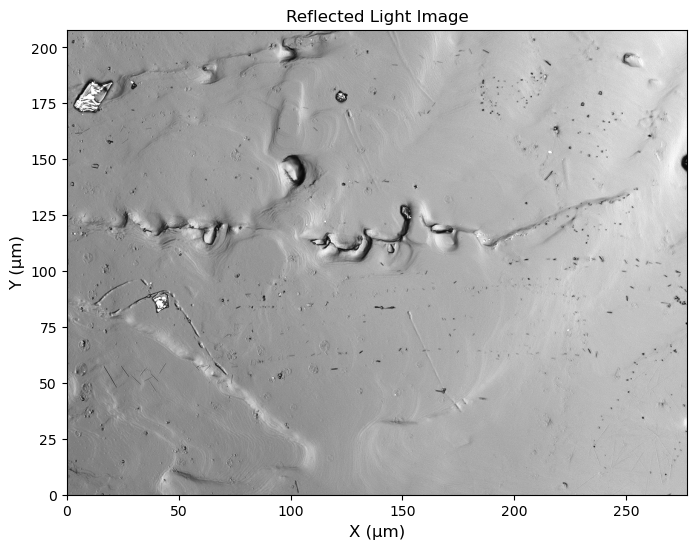

In [ ]:
ax = plot_vk4_reflected_light(data_1_vk4)
plt.savefig('plot group meeting reflected light.jpeg')

[]

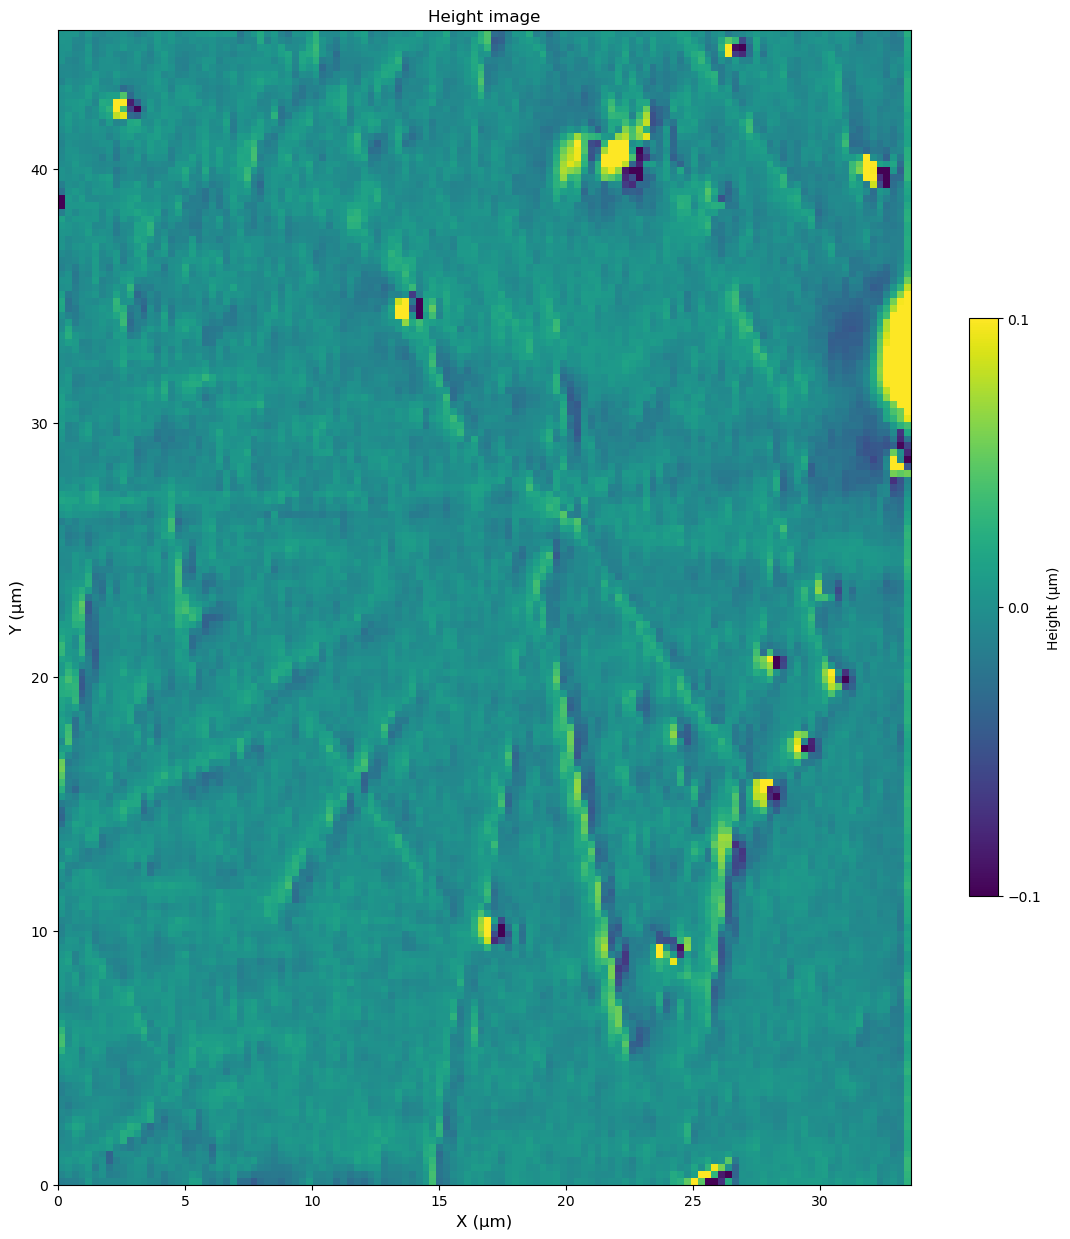

In [ ]:
cropped = crop_Vk4File_map(data_1_vk4_enhanced, x0=900, x1=None, y0=600, y1=None)

ax = plot_vk4_height(cropped, data_type='feature_enhanced')
plt.plot()

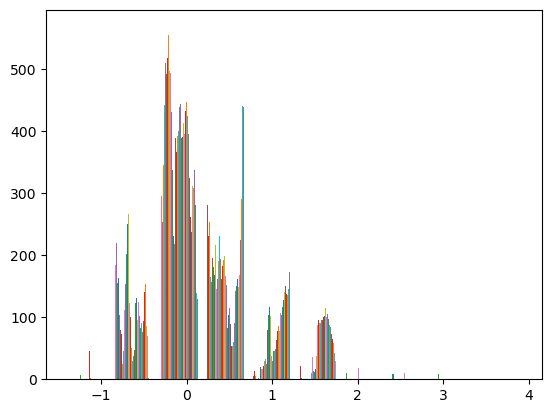

In [ ]:
plt.hist(data_1_vk4_tiltcorr['baseplane_subtracted'])
plt.show()
#print(data_2_vk4_tiltcorr['baseplane_subtracted'])#['img_height_data'])
#print(data_2_vk4['img_height_data'])

[0.26590577 0.29630101 0.29769624 ... 0.42731263 0.44970787 0.47410311]


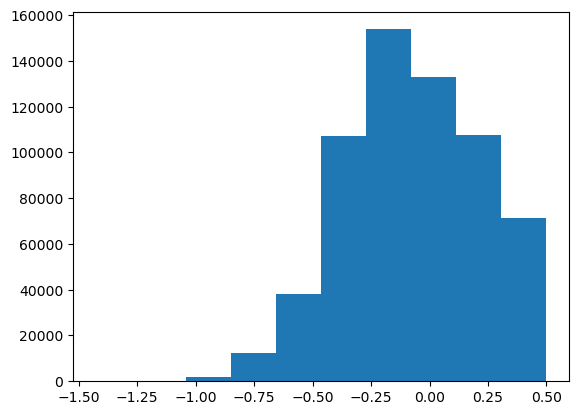

In [ ]:
import numpy as np

#data_processed = []
#for row in data_2_vk4_tiltcorr['baseplane_subtracted']:
#    for value in row:
#        if -0.5 <= value <= 0.5:
#            data_processed.append(value)

arr = data_1_vk4_tiltcorr['baseplane_subtracted']
data_processed = np.where((arr >= -0.5) & (arr <= 0.5), arr, 0)

#threshold = 0.5
#print(data_2_vk4_tiltcorr['baseplane_subtracted'][0])#.flatten()[data_2_vk4_tiltcorr['baseplane_subtracted'].flatten() < 0.5])
threshold = 0.5
data_processed = data_1_vk4_tiltcorr['baseplane_subtracted'].flatten()[data_1_vk4_tiltcorr['baseplane_subtracted'].flatten() < threshold]
data_processed_2 = data_processed[-threshold < data_processed]
print(data_processed)
plt.hist(data_processed)
plt.show()

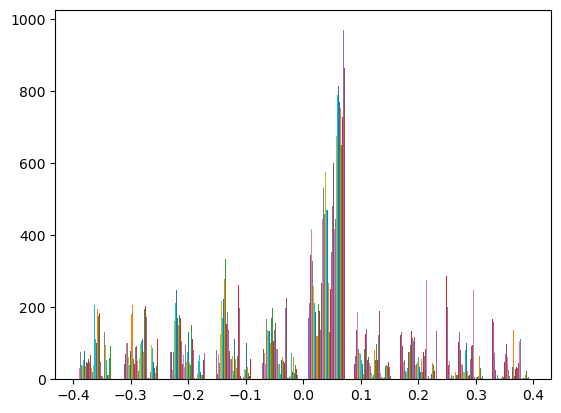

In [ ]:
data_processed = []

for row in data_2_vk4_tiltcorr['baseplane_subtracted']:
    processed_row = []
    for value in row:
        if -0.4 <= value <= 0.4:
            processed_row.append(value)
        else:
            processed_row.append(0)  # or 0, None, etc.
    data_processed.append(processed_row)

plt.hist(data_processed)
plt.show()

[]

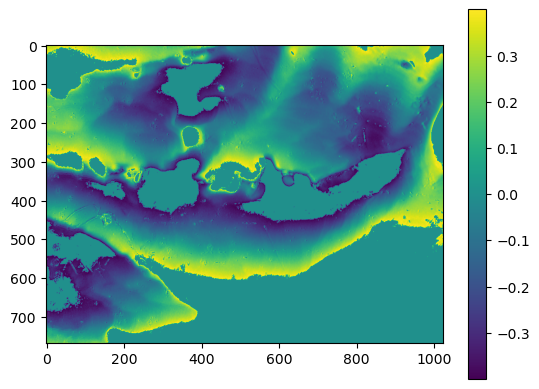

In [ ]:
i = plt.imshow(data_processed, cmap='viridis', origin='upper')
plt.colorbar(i)
plt.plot()

[]

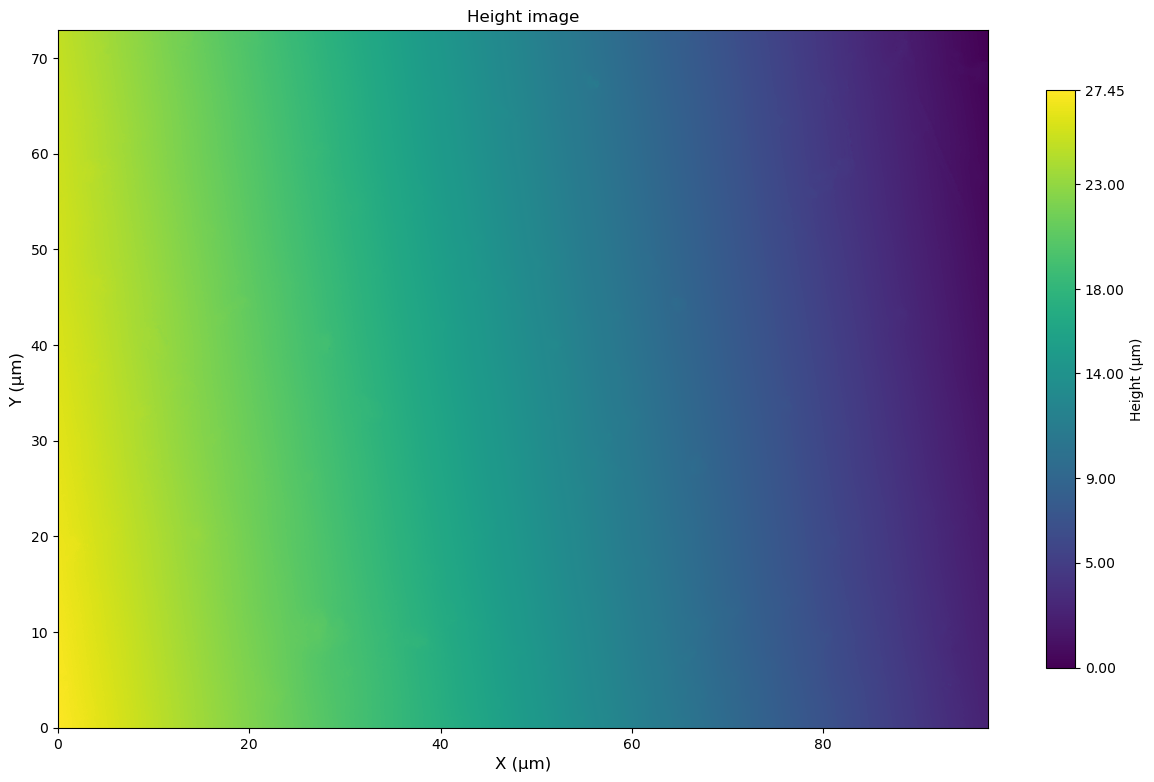

In [ ]:
file_name4 = Path("../raw_data_vk/Sample 3 Milan full/Stitched 150x/20260619161302_Y4_X1.vk4")

with open(file_name4, 'rb') as f:
    data_4_vk4 = parse_vk4_file(f)

ax = plot_vk4_height(data_4_vk4, data_type='original')
plt.plot()

[]

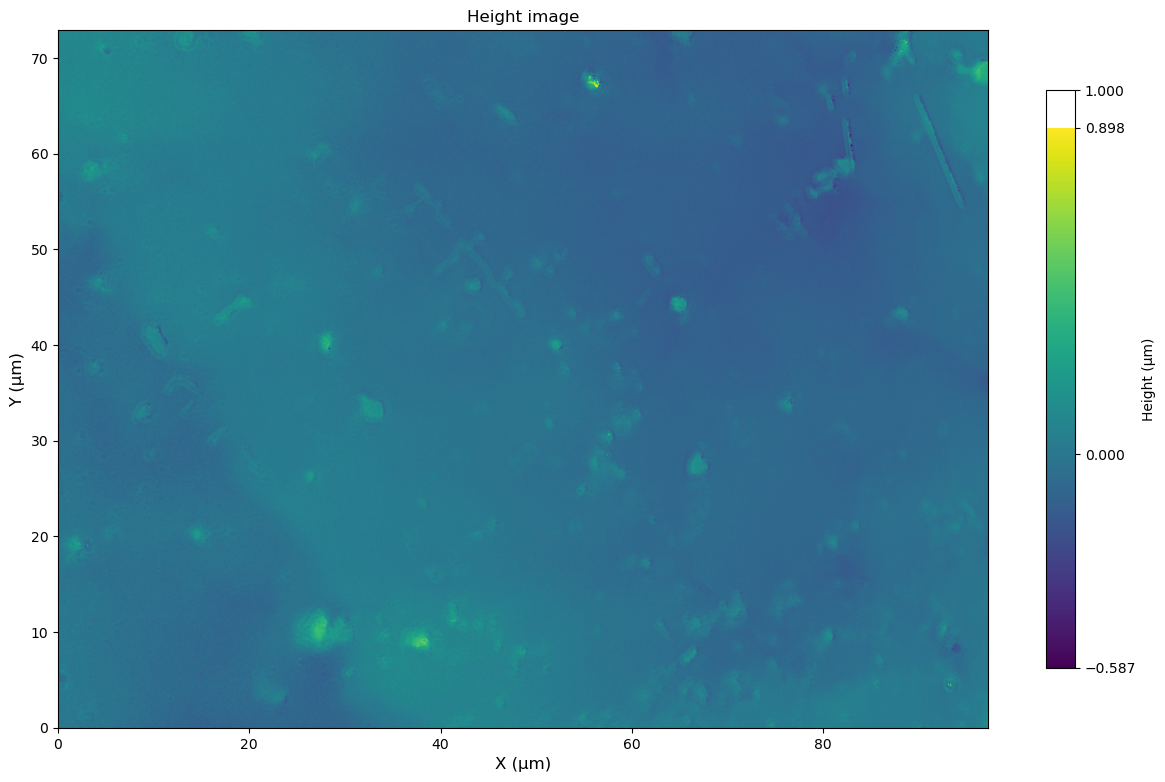

In [ ]:
file_name4 = Path("../raw_data_vk/Sample 3 Milan full/Stitched 150x/20260619161302_Y4_X1.vk4")

with open(file_name4, 'rb') as f:
    data_4_vk4 = parse_vk4_file(f)

data_4_vk4_tiltcorr = baseplane_filter(data_4_vk4, 50)

ax = plot_vk4_height(data_4_vk4_tiltcorr, data_type='baseplane_subtracted')
plt.plot()

[]

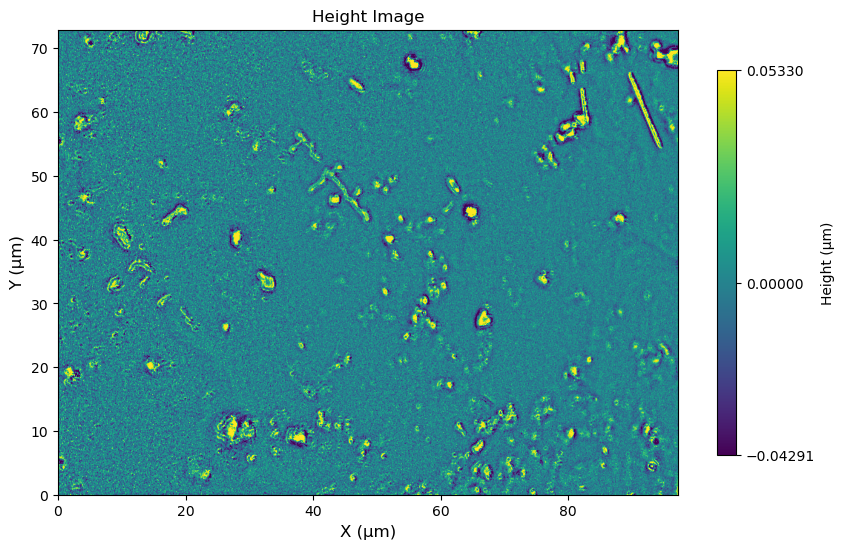

In [ ]:
file_name4 = Path("../raw_data_vk/Sample 3 Milan full/Stitched 150x/20260619161302_Y4_X1.vk4")

with open(file_name4, 'rb') as f:
    data_4_vk4 = parse_vk4_file(f)

data_4_vk4_tiltcorr = baseplane_filter(data_4_vk4, 50)
data_4_vk4_enhanced = feature_enhancement(data_4_vk4_tiltcorr)

ax = plot_vk4_height(data_4_vk4_enhanced, data_type='feature_enhanced')
#plt.savefig('plot 2 group meeting height.jpeg')
plt.plot()

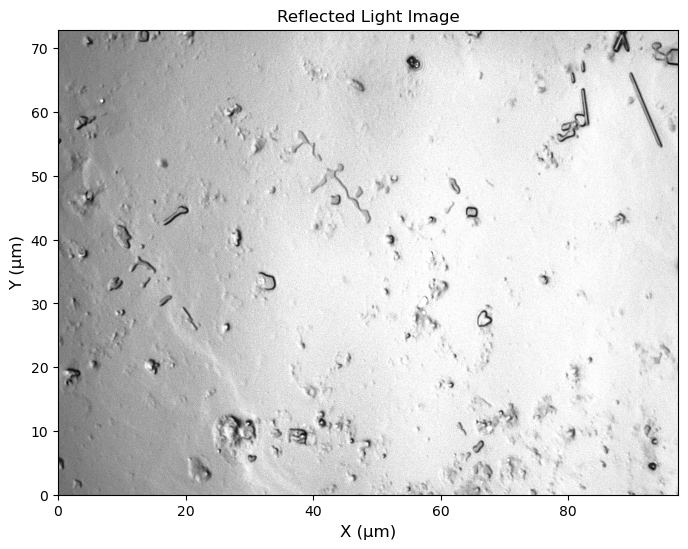

In [ ]:
ax = plot_vk4_reflected_light(data_4_vk4)
plt.savefig('plot 2 group meeting reflected light.jpeg')

[]

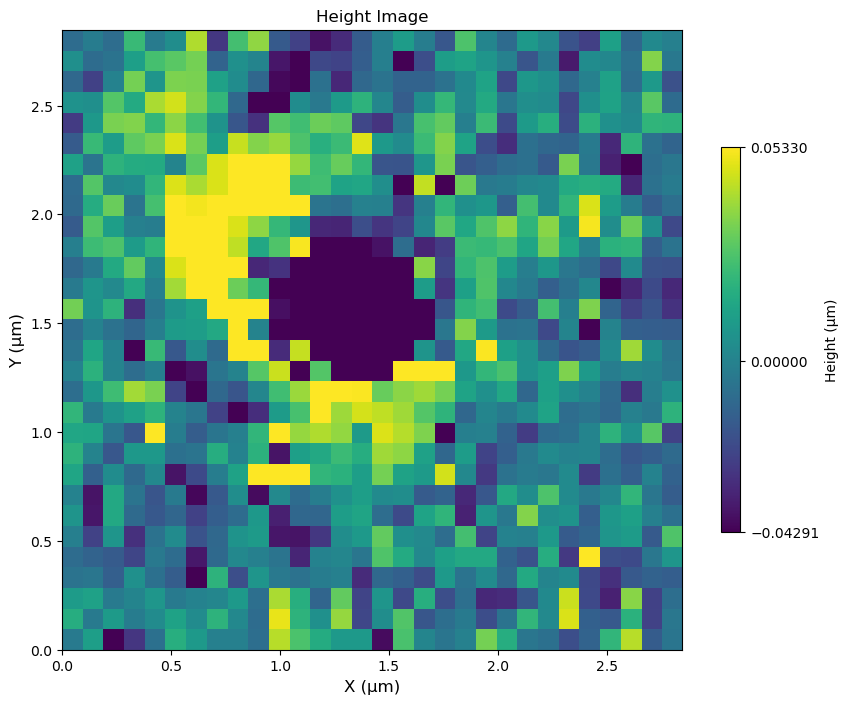

In [ ]:
cropped = crop_Vk4File_map(data_4_vk4_enhanced, x0=40, x1=70, y0=10, y1=40)


ax = plot_vk4_height(cropped, data_type='feature_enhanced')
#plt.savefig('small feature.jpeg')
plt.plot()

[]

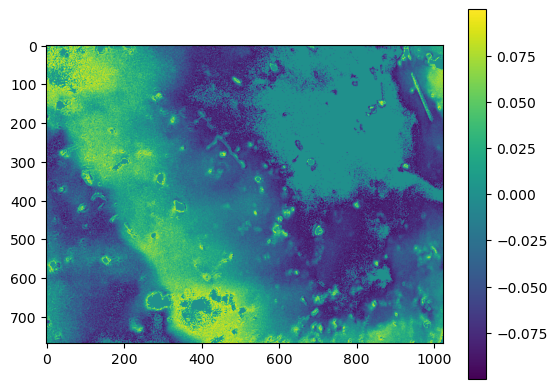

In [ ]:
data_processed2 = []

for row in data_4_vk4_tiltcorr['baseplane_subtracted']:
    processed_row2 = []
    for value in row:
        if -0.1 <= value <= 0.1:
            processed_row2.append(value)
        else:
            processed_row2.append(0)  # or 0, None, etc.
    data_processed2.append(processed_row2)

i = plt.imshow(data_processed2, cmap='viridis', origin='upper')
plt.colorbar(i)
plt.plot()

[]

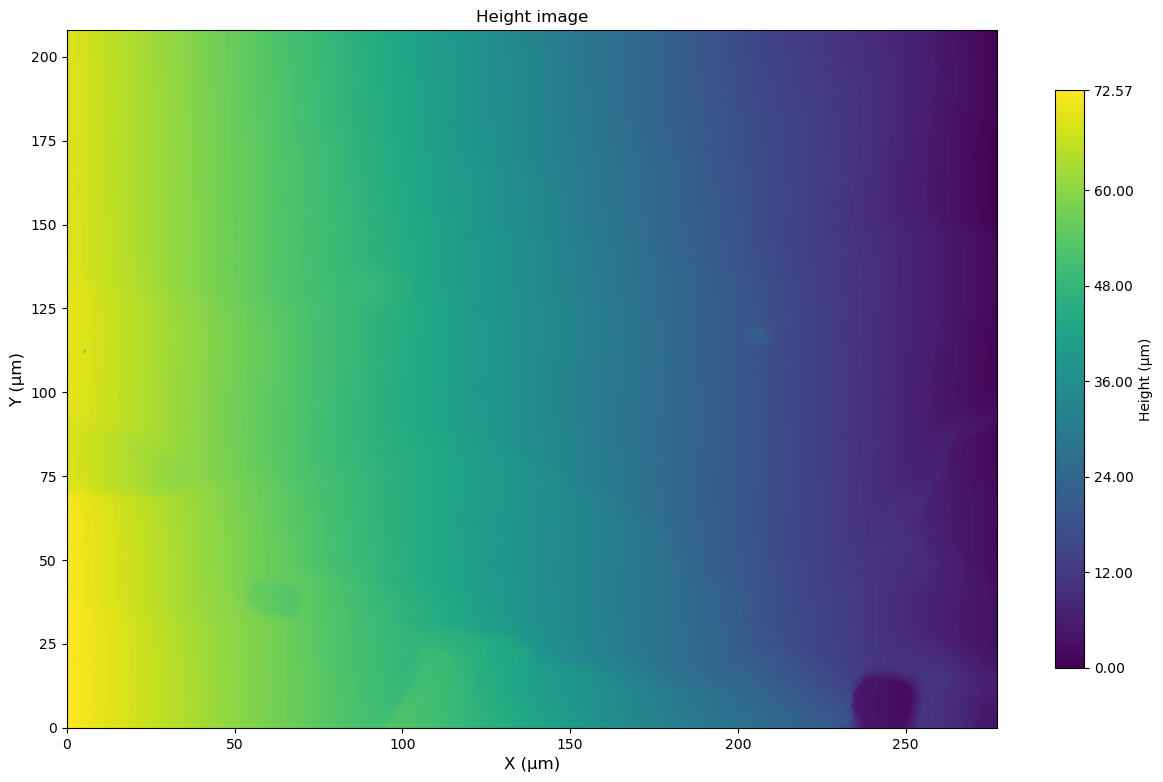

In [ ]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y2_X2.vk4")

with open(file_name, 'rb') as f:
    data_2_vk4 = parse_vk4_file(f)

ax = plot_vk4_height(data_2_vk4, data_type='original')
plt.plot()

[]

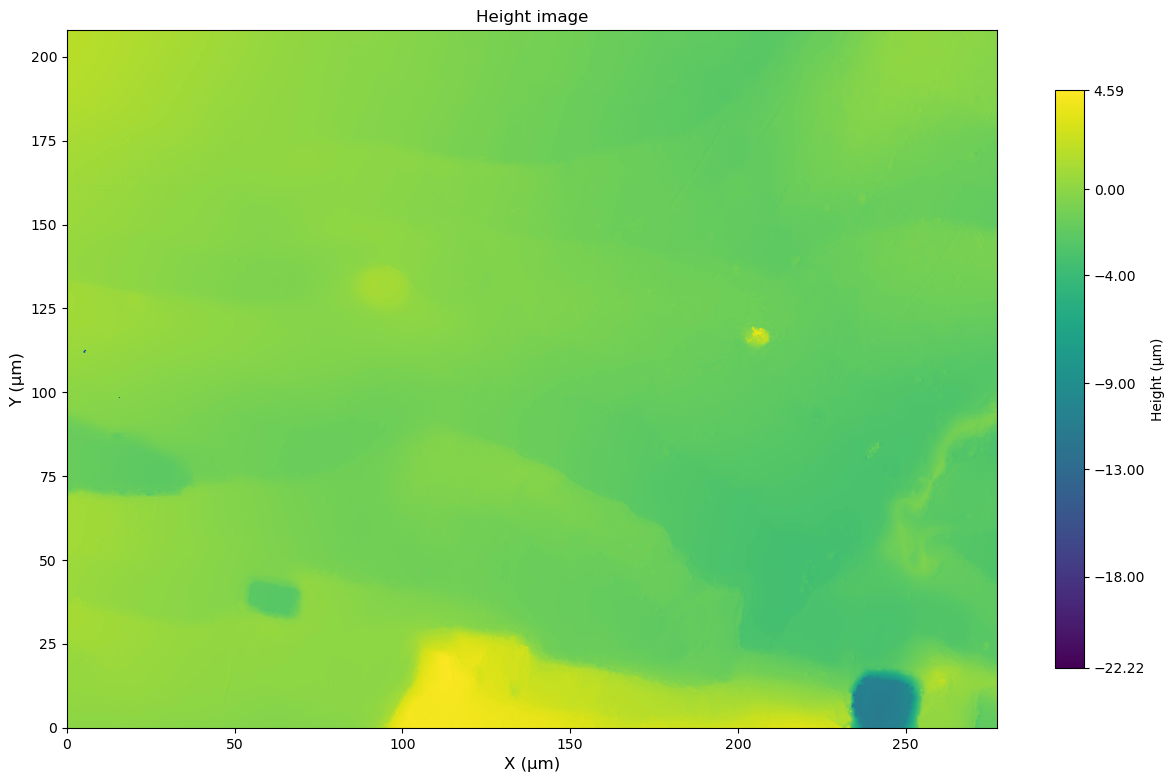

In [ ]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y2_X2.vk4")

with open(file_name, 'rb') as f:
    data_2_vk4 = parse_vk4_file(f)


data_2_vk4_tiltcorr = baseplane_filter(data_2_vk4, 60)

ax = plot_vk4_height(data_2_vk4_tiltcorr, data_type='baseplane_subtracted')
plt.plot()

[]

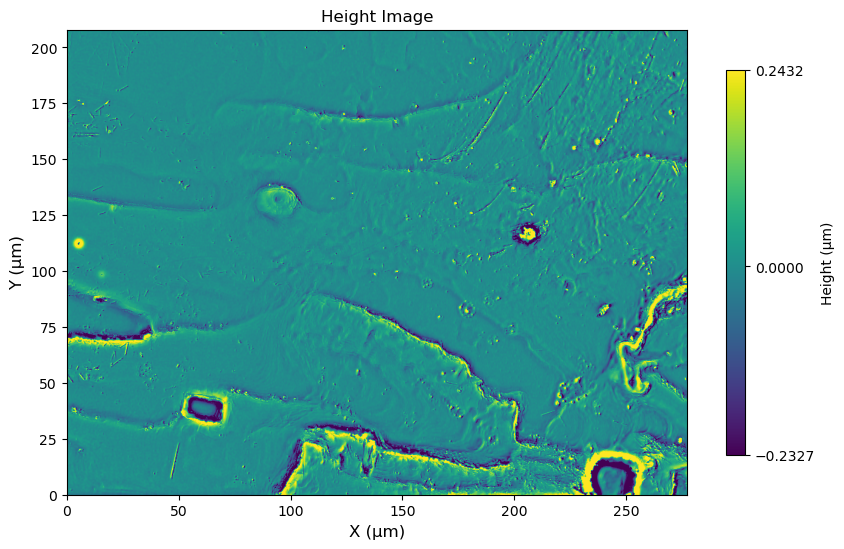

In [ ]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y2_X2.vk4")

with open(file_name, 'rb') as f:
    data_2_vk4 = parse_vk4_file(f)


data_2_vk4_tiltcorr = baseplane_filter(data_2_vk4, 60)
data_2_vk4_enhanced = feature_enhancement(data_2_vk4_tiltcorr)

ax = plot_vk4_height(data_2_vk4_enhanced, data_type='feature_enhanced')
plt.plot()

[]

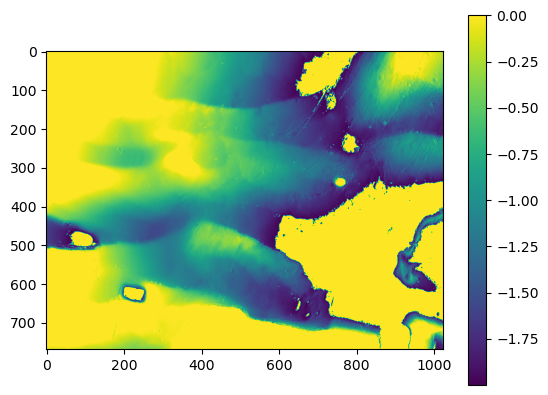

In [ ]:
data_processed3 = []

for row in data_3_vk4_tiltcorr['baseplane_subtracted']:
    processed_row3 = []
    for value in row:
        if -2 <= value <= 0:
            processed_row3.append(value)
        else:
            processed_row3.append(0)  # or 0, None, etc.
    data_processed3.append(processed_row3)

i = plt.imshow(data_processed3, cmap='viridis', origin='upper')
plt.colorbar(i)
plt.plot()

[]

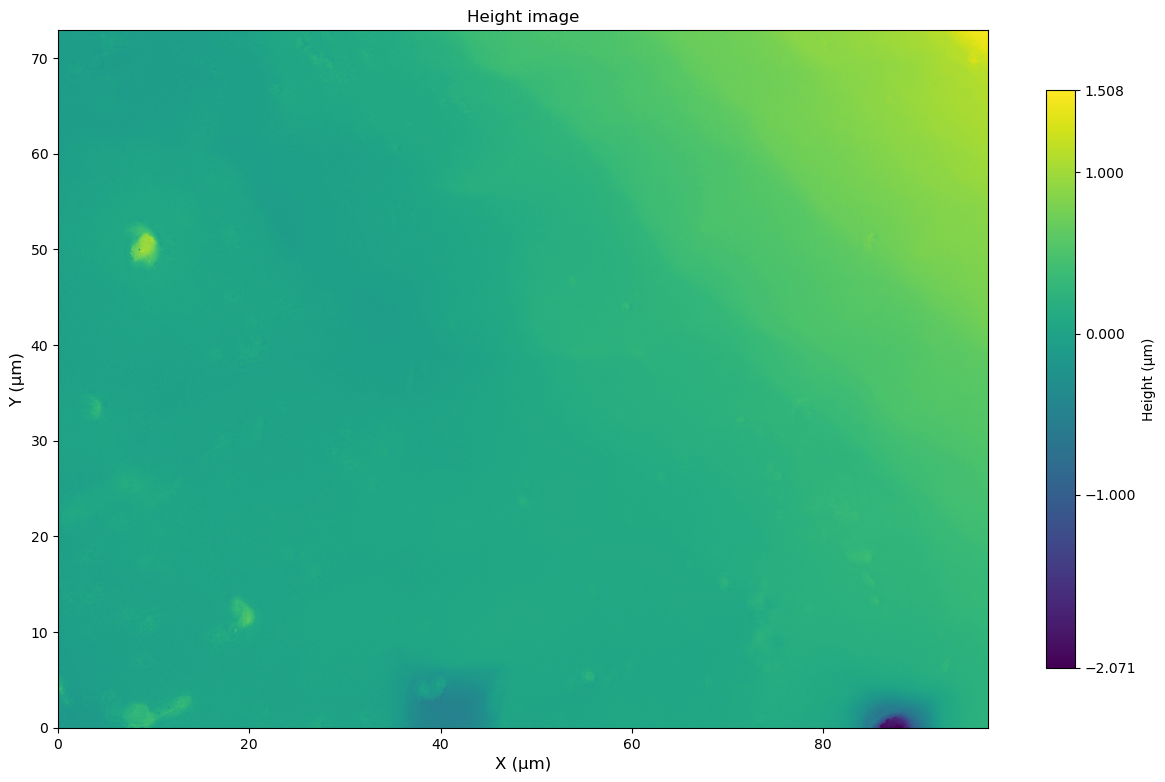

In [ ]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 150x/20260619161302_Y3_X2.vk4")

with open(file_name, 'rb') as f:
    data_3_vk4 = parse_vk4_file(f)


data_3_vk4_tiltcorr = baseplane_filter(data_3_vk4, 60)

ax = plot_vk4_height(data_3_vk4_tiltcorr, data_type='baseplane_subtracted')
plt.plot()

[]

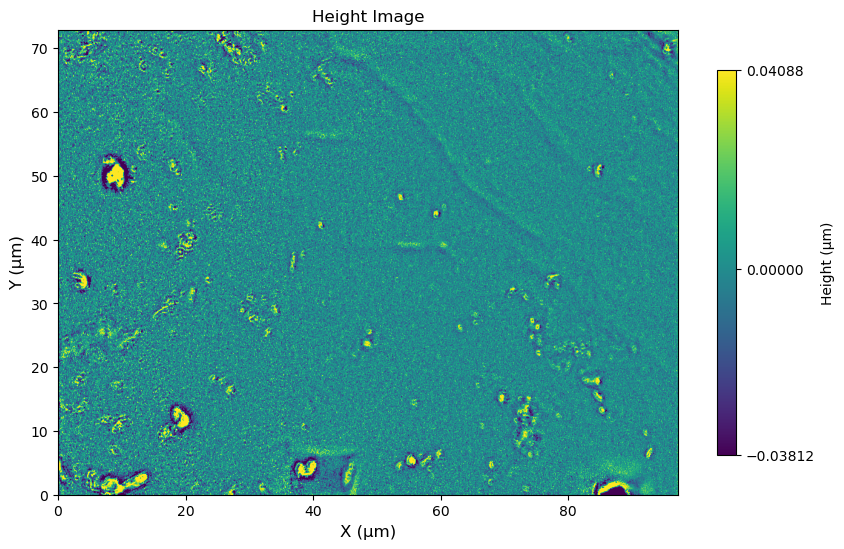

In [ ]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 150x/20260619161302_Y3_X2.vk4")

with open(file_name, 'rb') as f:
    data_3_vk4 = parse_vk4_file(f)


data_3_vk4_tiltcorr = baseplane_filter(data_3_vk4, 60)
data_3_vk4_enhanced = feature_enhancement(data_3_vk4_tiltcorr)

ax = plot_vk4_height(data_3_vk4_enhanced, data_type='feature_enhanced')
plt.plot()

[]

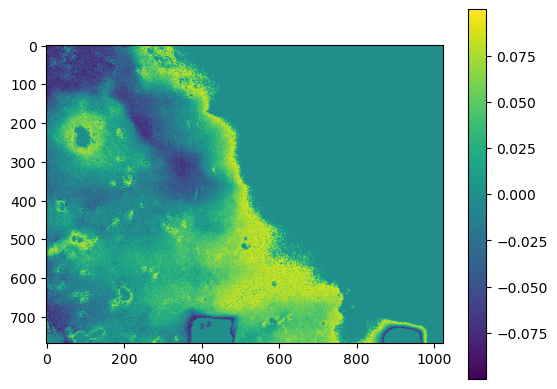

In [ ]:
data_processed3 = []

for row in data_3_vk4_tiltcorr['baseplane_subtracted']:
    processed_row3 = []
    for value in row:
        if -0.1 <= value <= 0.1:
            processed_row3.append(value)
        else:
            processed_row3.append(0)  # or 0, None, etc.
    data_processed3.append(processed_row3)

i = plt.imshow(data_processed3, cmap='viridis', origin='upper')
plt.colorbar(i)
plt.plot()

[]

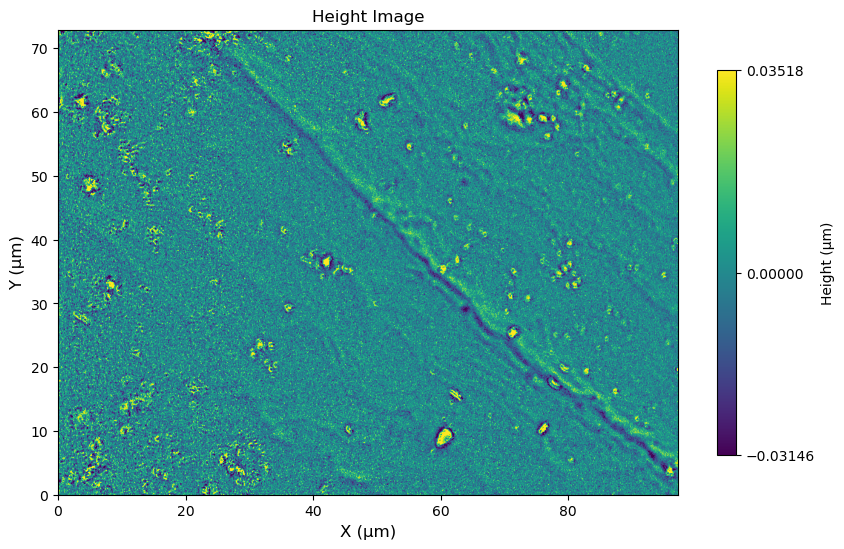

In [ ]:
file_name3 = Path("../raw_data_vk/Sample 3 Milan full/Stitched 150x/20260619161302_Y2_X2.vk4")

with open(file_name3, 'rb') as f:
    data_3_vk4 = parse_vk4_file(f)


data_3_vk4_tiltcorr = baseplane_filter(data_3_vk4, 60)
data_3_vk4_enhanced = feature_enhancement(data_3_vk4_tiltcorr)

ax = plot_vk4_height(data_3_vk4_enhanced, data_type='feature_enhanced')
plt.plot()